# Datos, exploración y ventanas (Persona A)

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import common as C, datos as D
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
raw = pd.read_csv(D.RAW_PATH, sep=";", decimal=",", index_col=0, parse_dates=True)
print(raw.shape, raw.index.min(), "->", raw.index.max())

(140256, 370) 2011-01-01 00:15:00 -> 2015-01-01 00:00:00


## 1. Del crudo a series horarias

In [ ]:
wide_raw = D.load_hourly_wide()
print("Horas por serie en 2012-2014:", len(wide_raw), "| NaN:", int(wide_raw.isna().sum().sum()))

Horas por serie en 2012-2014: 26304 | NaN: 0


## 2. Filtro de clientes y tamaño del panel

In [ ]:
active = wide_raw.columns[wide_raw.iloc[0] > 0]
wide_fix = D.fix_dst(wide_raw)
complete = D.complete_clients(wide_fix)
subset = D.pick_subset(complete)
panel = D.build_panel()
print(f"Clientes en el archivo:                       {wide_raw.shape[1]}")
print(f"Con consumo > 0 desde 2012-01-01 00:00:       {len(active)}  (los otros {wide_raw.shape[1]-len(active)} empiezan después)")
print(f"... y sin racha de ceros > 7 días (completos): {len(complete)}")
print(f"Subconjunto fijo (SEED={C.SEED}):                  {len(subset)}")
print(f"Observaciones horarias por serie:             {len(wide_raw):,}  (2012-01-01 a 2014-12-31 = 1096 días x 24)")
print(f"Panel completo (completos):                   {len(complete)*len(wide_raw):,}")
print(f"Panel usado (subconjunto):                    {len(panel):,}")

Clientes en el archivo:                       370
Con consumo > 0 desde 2012-01-01 00:00:       320  (los otros 50 empiezan después)
... y sin racha de ceros > 7 días (completos): 317
Subconjunto fijo (SEED=42):                  100
Observaciones horarias por serie:             26,304  (2012-01-01 a 2014-12-31 = 1096 días x 24)
Panel completo (completos):                   8,338,368
Panel usado (subconjunto):                    2,630,400


## 3. Cambio de horario

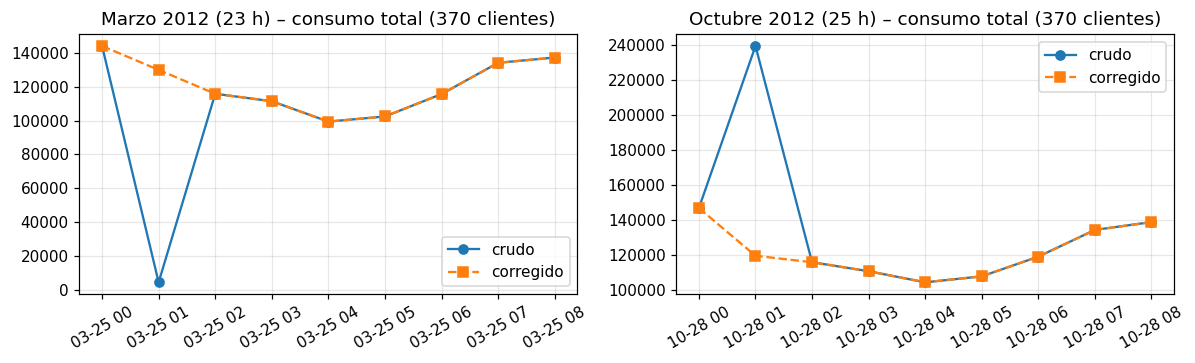

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, d, title in [(axs[0], D.DST_SPRING[0], "Marzo 2012 (23 h)"), (axs[1], D.DST_AUTUMN[0], "Octubre 2012 (25 h)")]:
    sl = slice(d, d + pd.Timedelta(hours=8))
    ax.plot(wide_raw.loc[sl].sum(axis=1), "o-", label="crudo")
    ax.plot(wide_fix.loc[sl].sum(axis=1), "s--", label="corregido"); ax.set_title(title + " – consumo total (370 clientes)")
    ax.legend(); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("figs/dst.png"); plt.show()

## 4. Perfil por hora, día de la semana y feriados de Portugal

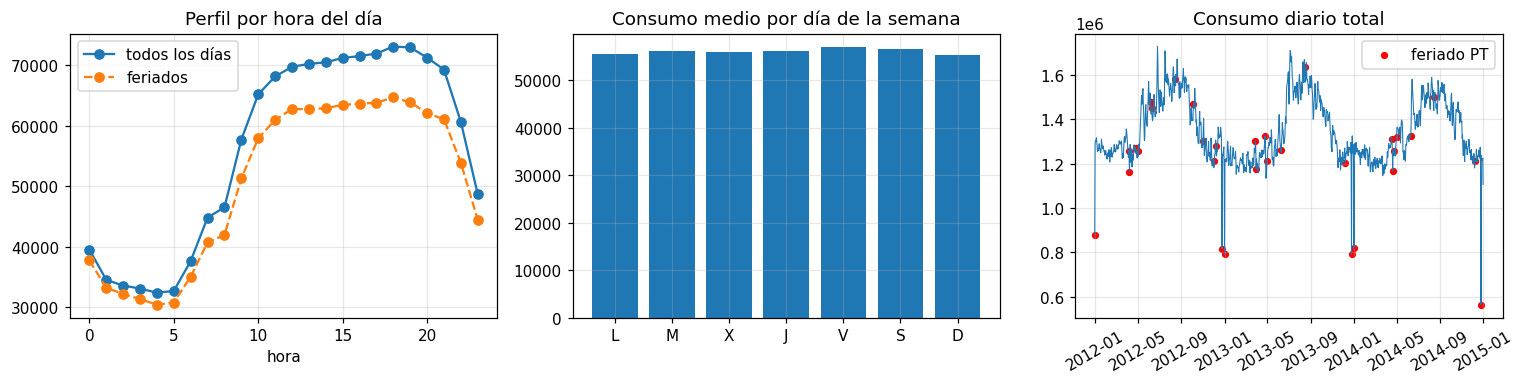

Feriados PT 2012-2014: 31


In [ ]:
w = D.panel_to_wide(panel)
total = w.sum(axis=1)
hol = D.pt_holidays()
is_hol = total.index.normalize().isin(hol)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
prof_h = total.groupby(total.index.hour).mean()
axs[0].plot(prof_h.index, prof_h.values, "o-", label="todos los días")
axs[0].plot(total[is_hol].groupby(total[is_hol].index.hour).mean(), "o--", label="feriados")
axs[0].set_title("Perfil por hora del día"); axs[0].set_xlabel("hora"); axs[0].legend()
dow = total.groupby(total.index.dayofweek).mean()
axs[1].bar(["L","M","X","J","V","S","D"], dow.values); axs[1].set_title("Consumo medio por día de la semana")
daily = total.resample("D").sum()
axs[2].plot(daily.index, daily.values, lw=.7); axs[2].scatter(daily.index[daily.index.isin(hol)], daily[daily.index.isin(hol)], c="r", s=14, label="feriado PT")
axs[2].set_title("Consumo diario total"); axs[2].legend(); axs[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("figs/perfiles.png"); plt.show()
print("Feriados PT 2012-2014:", len(hol))

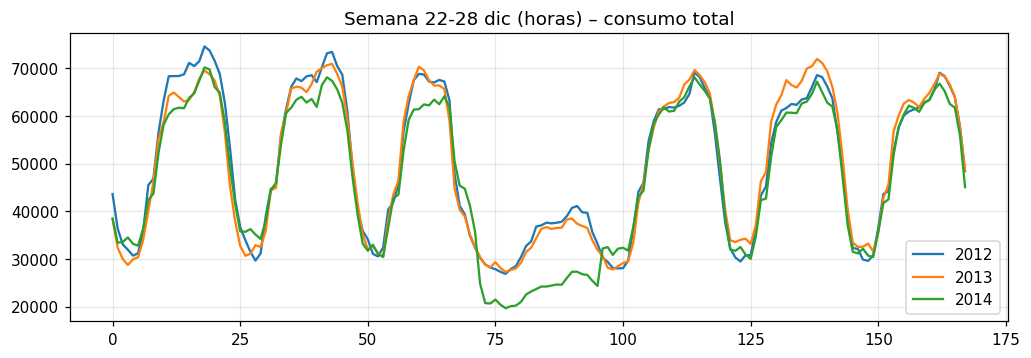

Consumo medio dic 1-14: 50,685 kWh/h | 24-26 dic: 40,992 (-19.1%) | 31 dic: 46,071 (-9.1%)
Día de Navidad vs lunes-viernes típico de dic: -54.0%


In [ ]:
# Navidad / Año Nuevo vs una semana típica de diciembre
def week_profile(y): 
    s = total[f"{y}-12-22":f"{y}-12-28"]; return s
fig, ax = plt.subplots(figsize=(11, 3.4))
for y in (2012, 2013, 2014):
    s = week_profile(y); ax.plot(np.arange(len(s)), s.values, label=str(y))
ax.set_title("Semana 22-28 dic (horas) – consumo total"); ax.legend(); plt.savefig("figs/navidad.png"); plt.show()
norm_dec = total["2014-12-01":"2014-12-14"].mean(); xmas = total["2014-12-24":"2014-12-26"].mean(); ny = total["2014-12-31":"2014-12-31"].mean()
print(f"Consumo medio dic 1-14: {norm_dec:,.0f} kWh/h | 24-26 dic: {xmas:,.0f} ({xmas/norm_dec-1:+.1%}) | 31 dic: {ny:,.0f} ({ny/norm_dec-1:+.1%})")
print(f"Día de Navidad vs lunes-viernes típico de dic: {total['2014-12-25'].mean()/total['2014-12-01':'2014-12-19'][total['2014-12-01':'2014-12-19'].index.dayofweek<5].mean()-1:+.1%}")

## 5. Escalas entre clientes y normalización

Consumo medio por cliente (kWh/h): mín 8.282 | mediana 153.51 | máx 11479.6 | razón máx/mín = 1,386


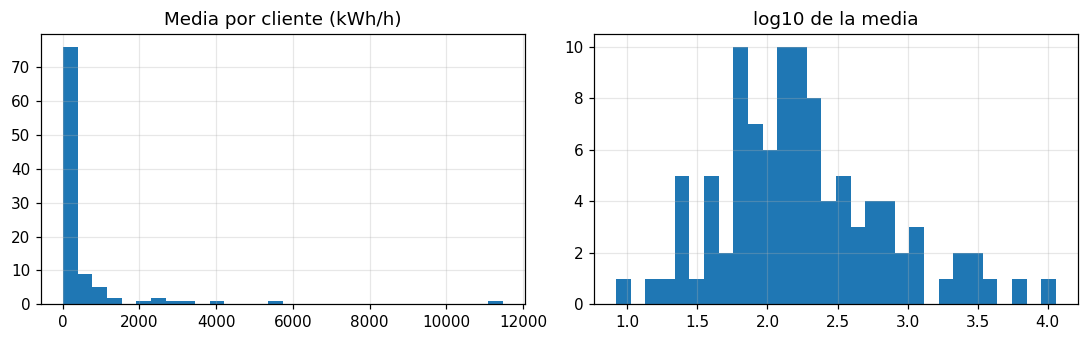

Horas con consumo exactamente 0: 28363 (1.08% del panel)


In [ ]:
m = w.loc[:C.TRAIN_END].mean()
print(f"Consumo medio por cliente (kWh/h): mín {m.min():.3f} | mediana {m.median():.2f} | máx {m.max():.1f} | razón máx/mín = {m.max()/max(m.min(),1e-9):,.0f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(m, bins=30); ax[0].set_title("Media por cliente (kWh/h)")
ax[1].hist(np.log10(m.clip(lower=1e-3)), bins=30); ax[1].set_title("log10 de la media")
plt.tight_layout(); plt.savefig("figs/escalas.png"); plt.show()
print("Horas con consumo exactamente 0:", int((w == 0).sum().sum()), f"({(w==0).mean().mean():.2%} del panel)")

In [ ]:
scaler = D.SeriesScaler().fit(w)
wn = scaler.transform(w)
print("Media/Desv. de las series normalizadas en train:", wn.loc[:C.TRAIN_END].mean().abs().max().round(6), wn.loc[:C.TRAIN_END].std().round(3).unique())
print("Media normalizada en prueba (cambio de nivel):", wn.loc[C.TEST_START:].mean().mean().round(3))
assert np.allclose(scaler.inverse(wn).values, w.values)

Media/Desv. de las series normalizadas en train: 0.0 [1.]
Media normalizada en prueba (cambio de nivel): -0.038


## 6. Covariables de calendario

In [ ]:
cal = D.calendar_features(w.index); display(cal.head(3)); print(cal.shape, "feriado = 1 en", int(cal.holiday.sum()), "horas")

,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos,holiday
ds,,,,,,,
2012-01-01 00:00:00,0.000000,1.000000,-0.781831,0.62349,0.0,1.0,1.0
2012-01-01 01:00:00,0.258819,0.965926,-0.781831,0.62349,0.0,1.0,1.0
2012-01-01 02:00:00,0.500000,0.866025,-0.781831,0.62349,0.0,1.0,1.0


(26304, 7) feriado = 1 en 744 horas


## 7. `Dataset` de ventanas (L = 168, H = 24, stride = 1 h)

In [ ]:
counts = D.count_windows(wn, L=168, H=24)
per = {k: v // wn.shape[1] for k, v in counts.items()}
print("Ventanas (100 clientes):", counts, "| por cliente:", per)
ds = D.WindowDataset(wn, "train", return_future=True)
x, xf, y = ds[0]; print("x", tuple(x.shape), "x_future", tuple(xf.shape), "y", tuple(y.shape))
batch = next(iter(torch.utils.data.DataLoader(D.WindowDataset(wn, "train"), batch_size=64, shuffle=True)))
print("batch:", [tuple(t.shape) for t in batch])

Ventanas (100 clientes): {'train': 2169700, 'val': 218500, 'test': 218500} | por cliente: {'train': 21697, 'val': 2185, 'test': 2185}
x (168, 8) x_future (24, 7) y (24,)


batch: [(64, 168, 8), (64, 24)]


## 8. Auditoría de fugas
Cada entrada de la red debe poder calcularse en el instante en que se emite el pronóstico (00:00, con datos hasta 23:00).

In [ ]:
# Fuga 1 – split aleatorio de ventanas: aquí el split es CRONOLÓGICO por fecha del objetivo.
tr, va, te = (D.WindowDataset(wn, s) for s in ("train", "val", "test"))
last_train_target = tr.ds[tr.starts[-1] + 23]; first_val_target = va.ds[va.starts[0]]; first_test_target = te.ds[te.starts[0]]
assert last_train_target <= C.TRAIN_END < first_val_target and va.ds[va.starts[-1] + 23] <= C.VAL_END < first_test_target
print("OK: último objetivo train", last_train_target, "< primer objetivo val", first_val_target, "< primer objetivo test", first_test_target)
# Contraste: con un split aleatorio, ventanas de train con stride 1 solapan 167/168 horas con las de test.
rng = np.random.default_rng(0); idx = rng.permutation(len(tr.starts)); a, b = np.sort(tr.starts[idx[:1000]]), tr.starts[idx[1000:2000]]
print("Contraste (aleatorio): fracción de ventanas 'test' que solapan ≥1 h de input/objetivo con alguna de train:",
      np.mean([np.any(np.abs(a - s) < 168 + 24) for s in b]).round(2))

OK: último objetivo train 2014-06-30 23:00:00 < primer objetivo val 2014-07-01 00:00:00 < primer objetivo test 2014-10-01 00:00:00
Contraste (aleatorio): fracción de ventanas 'test' que solapan ≥1 h de input/objetivo con alguna de train: 1.0


In [ ]:
# Fuga 2 – escalar con toda la serie: el scaler se ajusta SOLO con train.
assert scaler.mean_.equals(w.loc[:C.TRAIN_END].mean())
leak = w.mean(); print("Diferencia relativa media/escala si se hubiera usado toda la serie:", ((leak - scaler.mean_).abs() / scaler.std_).mean().round(3), "desv. estándar")

Diferencia relativa media/escala si se hubiera usado toda la serie: 0.031 desv. estándar


In [ ]:
# Fuga 3 – early stopping con la prueba: los entrenamientos reciben train y val; el test solo se evalúa al final.
import inspect
print("Datasets disponibles para entrenar/elegir:", ["train", "val"], "| test solo en backtest()")
assert va.ds[va.starts[0]] > C.TRAIN_END and va.ds[va.starts[-1] + 23] <= C.VAL_END   # val no toca octubre-diciembre

Datasets disponibles para entrenar/elegir: ['train', 'val'] | test solo en backtest()


In [ ]:
# Fuga 4 – covariables mal alineadas: el calendario de la ventana i coincide exactamente con las horas de X (pasado) e y (futuro).
x, xf, y = D.WindowDataset(wn, "test", return_future=True)[5]
s = te.starts[5]; ts_in = te.ds[s - 168:s]; ts_out = te.ds[s:s + 24]
assert torch.allclose(x[:, 1:], torch.tensor(D.calendar_features(ts_in).to_numpy(dtype="float32")))
assert torch.allclose(xf,       torch.tensor(D.calendar_features(ts_out).to_numpy(dtype="float32")))
assert ts_in[-1] < ts_out[0] and (ts_out[0] - ts_in[-1]) == pd.Timedelta("1h")
# El calendario SÍ se puede usar a futuro (hora/día/mes/feriado son conocidos); el consumo y cualquier rezago de él, no.
assert torch.equal(x[:, 0], torch.tensor(wn.loc[ts_in].iloc[:, 0].to_numpy(dtype="float32")))  # canal 0 solo contiene pasado
print("OK: X termina a las", ts_in[-1], "e y empieza a las", ts_out[0])

OK: X termina a las 2014-10-01 04:00:00 e y empieza a las 2014-10-01 05:00:00
